# CNN architecture comparison

Classifies photos of 73 objects plus a `background` class. Two CNNs are trained from scratch (a VGG-style CNN and a small ResNet) and three ImageNet models are fine-tuned (MobileNetV2, EfficientNetB0, ResNet50V2).

## 1. Setup

In [ ]:
import os, time, json, shutil, zipfile, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Config

In [ ]:
DRIVE_ZIP_PATH = "/content/drive/MyDrive/images.zip"
RESULTS_DIR = "/content/drive/MyDrive/cnn_results"
RESULTS_CSV = f"{RESULTS_DIR}/results.csv"
LOCAL_DATA_DIR = "/content/data"

IMG_SIZE = 224
BATCH_SIZE = 32
VAL_FRAC, TEST_FRAC = 0.15, 0.15

MODELS_TO_RUN = ["custom_cnn", "mini_resnet", "mobilenetv2", "efficientnetb0", "resnet50v2"]
EPOCHS_SCRATCH = 60
EPOCHS_HEAD = 15         # transfer learning, phase 1: base frozen
EPOCHS_FINETUNE = 20     # transfer learning, phase 2: top of the base unfrozen
FINETUNE_FRACTION = 0.3  # share of base layers unfrozen in phase 2

os.makedirs(RESULTS_DIR, exist_ok=True)

## 3. Load the data

In [ ]:
data_dir = Path(LOCAL_DATA_DIR)

if not any(data_dir.glob("images_*")):
    with zipfile.ZipFile(DRIVE_ZIP_PATH) as z:
        z.extractall(data_dir)

for folder in list(data_dir.rglob("images_*")):
    if folder.is_dir() and folder.parent != data_dir and "__MACOSX" not in folder.parts:
        shutil.move(folder, data_dir / folder.name)

n_folders = len(list(data_dir.glob("images_*")))
assert n_folders, "No images_* folders found, check DRIVE_ZIP_PATH"
print(n_folders, "folders ready")

## 4. Label and clean the images

Each image is labelled by its folder (`images_OBJ052` to `OBJ052`). Files with `_bg_` in the name go into one shared `background` class. Images with the wrong size or colour mode are fixed when they're loaded.

In [ ]:
rows, problems = [], []
for folder in sorted(data_dir.glob("images_*")):
    obj_id = folder.name.removeprefix("images_")
    for f in sorted(folder.glob("*")):
        if f.name.startswith(".") or f.suffix.lower() not in (".jpg", ".jpeg"):
            continue
        with Image.open(f) as im:
            if im.size != (IMG_SIZE, IMG_SIZE) or im.mode != "RGB":
                problems.append(f"{f.name}: {im.size}, {im.mode}")
        is_bg = "_bg_" in f.name.lower()
        rows.append({"path": str(f), "label": "background" if is_bg else obj_id,
                     "folder": folder.name, "is_bg": is_bg})

df = pd.DataFrame(rows)
print(f"{len(df)} images")
if problems:
    print("Resized or converted when loading:", *problems, sep="\n  ")

Some files appear more than once. Where a "background" photo is a copy of an object photo, the background copy is dropped; for all other duplicates one copy is kept. MD5 byte identical hash was used to check if duplicated existed

In [ ]:
df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df.path]
two_labels = df.groupby("md5").label.transform("nunique") > 1
df = df[~(two_labels & df.is_bg)].drop_duplicates("md5").reset_index(drop=True)

CLASS_NAMES = sorted(df.label.unique())
NUM_CLASSES = len(CLASS_NAMES)
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
print(f"Removed {len(rows) - len(df)} duplicates: {len(df)} images, {NUM_CLASSES} classes")

## 5. Train / validation / test split

A stratified 70/15/15 split, saved to Drive so every model and every session uses the same images.

In [ ]:
split_path = f"{RESULTS_DIR}/split.csv"
if os.path.exists(split_path):
    split_df = pd.read_csv(split_path)
    assert set(split_df.path) == set(df.path), "The dataset has changed since split.csv was saved"
else:
    train_df, temp_df = train_test_split(df, test_size=VAL_FRAC + TEST_FRAC, stratify=df.label, random_state=SEED)
    val_df, test_df = train_test_split(temp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=temp_df.label, random_state=SEED)
    split_df = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
    split_df.to_csv(split_path, index=False)

train_df = split_df[split_df.split == "train"].reset_index(drop=True)
val_df = split_df[split_df.split == "val"].reset_index(drop=True)
test_df = split_df[split_df.split == "test"].reset_index(drop=True)
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

# background has 4x more images than an object class, so weight the classes
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES),
                               y=train_df.label.map(class_to_idx).values)
CLASS_WEIGHT = dict(enumerate(weights))

train 5120 | val 1097 | test 1098


## 6. Input pipeline

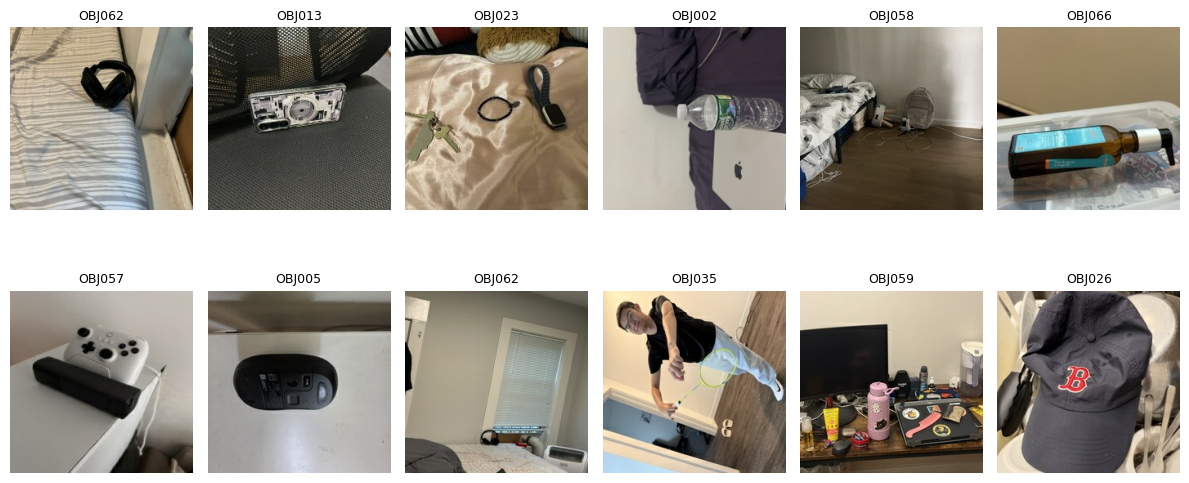

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), label  # uint8 keeps the cache small

def make_ds(d, training):
    labels = d.label.map(class_to_idx).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y))
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df, training=False)
test_ds = make_ds(test_df, training=False)

x, y = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[y[i]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Models

Augmentation is part of each model, so it only runs during training. Every model takes raw 0–255 pixels and rescales them the way it expects.

In [ ]:
def augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
    ], name="augmentation")

def conv_bn_relu(x, filters, kernel=3, strides=1):
    x = layers.Conv2D(filters, kernel, strides=strides, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

def head(x, dropout):
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return layers.Dense(NUM_CLASSES, activation="softmax")(x)


# VGG-style CNN: 224 -> 112 -> 56 -> 28 -> 14
def build_custom_cnn():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation()(inputs)
    x = layers.Rescaling(1 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = conv_bn_relu(x, filters)
        x = conv_bn_relu(x, filters)
        x = layers.MaxPooling2D()(x)
        x = layers.SpatialDropout2D(0.1)(x)
    return keras.Model(inputs, head(x, 0.4), name="custom_cnn")


def residual_block(x, filters, strides=1):
    shortcut = x
    x = conv_bn_relu(x, filters, strides=strides)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if strides != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=strides, use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    return layers.ReLU()(layers.Add()([x, shortcut]))

# Small ResNet: stem down to 56x56, then residual blocks down to 7x7x512
def build_mini_resnet():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation()(inputs)
    x = layers.Rescaling(1 / 255)(x)
    x = conv_bn_relu(x, 32, kernel=5, strides=2)
    x = layers.MaxPooling2D()(x)
    for filters, strides in [(64, 1), (64, 1), (128, 2), (128, 1), (256, 2), (256, 1), (512, 2)]:
        x = residual_block(x, filters, strides)
    return keras.Model(inputs, head(x, 0.4), name="mini_resnet")


# Pretrained models and the input scaling each expects (EfficientNet rescales internally)
PRETRAINED = {
    "mobilenetv2": (keras.applications.MobileNetV2, lambda: layers.Rescaling(1 / 127.5, offset=-1)),
    "efficientnetb0": (keras.applications.EfficientNetB0, None),
    "resnet50v2": (keras.applications.ResNet50V2, lambda: layers.Rescaling(1 / 127.5, offset=-1)),
}

def build_transfer(name):
    app, rescale = PRETRAINED[name]
    base = app(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation()(inputs)
    if rescale:
        x = rescale()(x)
    x = base(x, training=False)  # keeps BatchNorm in inference mode, also while fine-tuning
    return keras.Model(inputs, head(x, 0.3), name=name), base

def unfreeze_top(base, fraction):
    base.trainable = True
    cutoff = int(len(base.layers) * (1 - fraction))
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= cutoff and not isinstance(layer, layers.BatchNormalization)


SCRATCH_BUILDERS = {"custom_cnn": build_custom_cnn, "mini_resnet": build_mini_resnet}

for name in MODELS_TO_RUN:
    model = SCRATCH_BUILDERS[name]() if name in SCRATCH_BUILDERS else build_transfer(name)[0]
    print(f"{name:16s} {model.count_params():>12,} params")
del model
keras.backend.clear_session()

custom_cnn          1,194,154 params
mini_resnet         6,478,122 params
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
mobilenetv2         2,352,778 params
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
efficientnetb0      4,144,365 params
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
resnet50v2         23,716,426 params


## 8. Training

Models trained from scratch use Adam (lr 1e-3). Pretrained models first train only the new head, then fine-tune the top of the base at lr 1e-5. Each finished model is saved to Drive with its history and test predictions, and models already in `results.csv` are skipped.

In [ ]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def fit(model, epochs, patience):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=max(2, patience // 3), min_lr=1e-7),
    ]
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=2)
    return {k: [float(v) for v in vals] for k, vals in h.history.items()}

def run_experiment(name):
    start = time.time()
    if name in SCRATCH_BUILDERS:
        model = SCRATCH_BUILDERS[name]()
        compile_model(model, 1e-3)
        history = fit(model, EPOCHS_SCRATCH, patience=10)
        finetune_start = None
    else:
        model, base = build_transfer(name)
        print("Phase 1: training the new head (pretrained layers frozen)")
        compile_model(model, 1e-3)
        h1 = fit(model, EPOCHS_HEAD, patience=4)
        print(f"Phase 2: fine-tuning top {FINETUNE_FRACTION:.0%} of {name}")
        unfreeze_top(base, FINETUNE_FRACTION)
        compile_model(model, 1e-5)  # recompile so the trainable changes take effect
        h2 = fit(model, EPOCHS_FINETUNE, patience=5)
        history = {k: h1[k] + h2.get(k, []) for k in h1}
        finetune_start = len(h1["loss"])
    train_time = time.time() - start

    y_true = test_df.label.map(class_to_idx).values
    y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)

    # inference time per image, averaged over 10 batches after a warm-up call
    xb = next(iter(test_ds))[0]
    model(xb, training=False)
    t = time.time()
    for _ in range(10):
        model(xb, training=False)
    ms_per_image = (time.time() - t) / (10 * len(xb)) * 1000

    model.save(f"{RESULTS_DIR}/{name}.keras")
    np.save(f"{RESULTS_DIR}/{name}_pred.npy", y_pred)
    with open(f"{RESULTS_DIR}/{name}_history.json", "w") as f:
        json.dump({"history": history, "finetune_start": finetune_start}, f)

    return {"model": name,
            "type": "from scratch" if name in SCRATCH_BUILDERS else "transfer learning",
            "params": model.count_params(),
            "epochs": len(history["loss"]),
            "best_val_acc": max(history["val_accuracy"]),
            "test_acc": accuracy_score(y_true, y_pred),
            "test_macro_f1": f1_score(y_true, y_pred, average="macro"),
            "train_time_min": train_time / 60,
            "ms_per_image": ms_per_image}

In [ ]:
results = pd.read_csv(RESULTS_CSV).to_dict("records") if os.path.exists(RESULTS_CSV) else []
done = {r["model"] for r in results}

for name in MODELS_TO_RUN:
    if name in done:
        print(f"Skipping {name} (already in results.csv)")
        continue
    print("\n" + "=" * 70 + f"\n{name}\n" + "=" * 70)
    results.append(run_experiment(name))
    pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
    print(f"{name}: test accuracy {results[-1]['test_acc']:.3f}")
    keras.backend.clear_session()


custom_cnn
Epoch 1/60
160/160 - 76s - 475ms/step - accuracy: 0.0295 - loss: 4.3413 - val_accuracy: 0.0164 - val_loss: 4.4823 - learning_rate: 0.0010
Epoch 2/60
160/160 - 58s - 363ms/step - accuracy: 0.0631 - loss: 4.0417 - val_accuracy: 0.0264 - val_loss: 4.4363 - learning_rate: 0.0010
Epoch 3/60
160/160 - 58s - 364ms/step - accuracy: 0.0699 - loss: 3.8870 - val_accuracy: 0.0820 - val_loss: 3.9984 - learning_rate: 0.0010
Epoch 4/60
160/160 - 59s - 368ms/step - accuracy: 0.0934 - loss: 3.7674 - val_accuracy: 0.1158 - val_loss: 3.7473 - learning_rate: 0.0010
Epoch 5/60
160/160 - 83s - 518ms/step - accuracy: 0.1072 - loss: 3.6801 - val_accuracy: 0.1313 - val_loss: 3.7561 - learning_rate: 0.0010
Epoch 6/60
160/160 - 60s - 377ms/step - accuracy: 0.1318 - loss: 3.5447 - val_accuracy: 0.1641 - val_loss: 3.5755 - learning_rate: 0.0010
Epoch 7/60
160/160 - 58s - 363ms/step - accuracy: 0.1484 - loss: 3.4599 - val_accuracy: 0.0802 - val_loss: 4.1672 - learning_rate: 0.0010
Epoch 8/60
160/160 - 5

## 9. Results

,model,type,params,epochs,best_val_acc,test_acc,test_macro_f1,train_time_min,ms_per_image
0,efficientnetb0,transfer learning,"4,144,365",35,0.941,0.942,0.949,11.4,11.51
1,mobilenetv2,transfer learning,"2,352,778",33,0.918,0.927,0.936,8.4,5.14
2,resnet50v2,transfer learning,"23,716,426",35,0.926,0.922,0.931,19.2,7.06
3,mini_resnet,from scratch,"6,478,122",60,0.869,0.875,0.885,27.7,1.96
4,custom_cnn,from scratch,"1,194,154",60,0.582,0.570,0.556,58.8,1.00


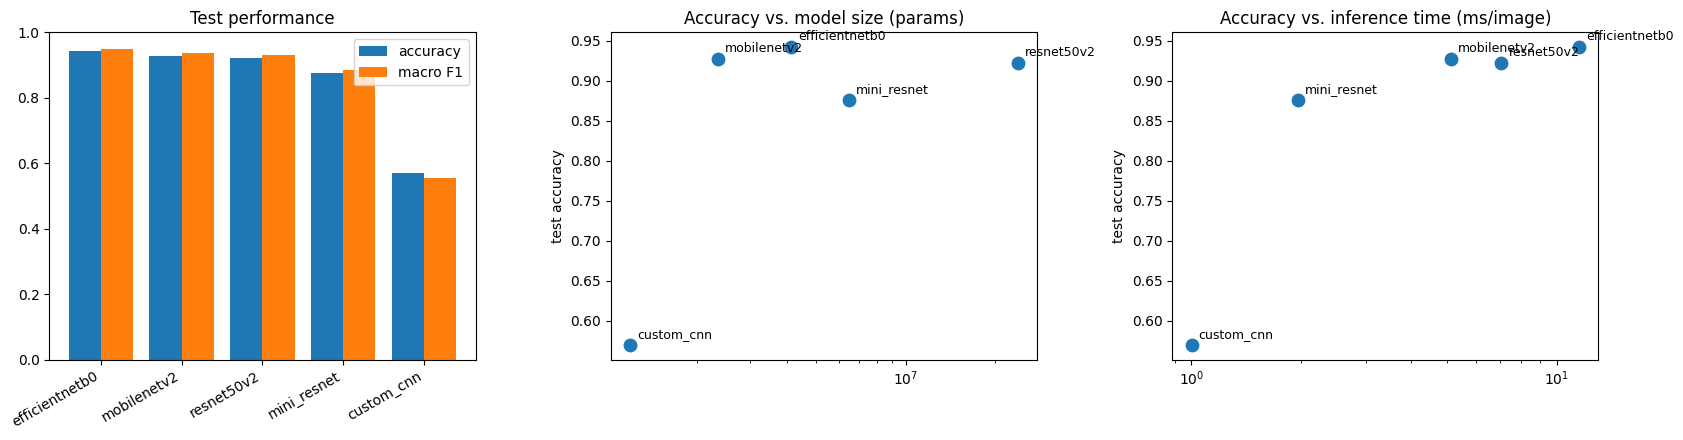

In [ ]:
res = pd.read_csv(RESULTS_CSV)
res = res[res.model.isin(MODELS_TO_RUN)].sort_values("test_acc", ascending=False).reset_index(drop=True)
display(res.style.format({"params": "{:,}", "best_val_acc": "{:.3f}", "test_acc": "{:.3f}",
                          "test_macro_f1": "{:.3f}", "train_time_min": "{:.1f}", "ms_per_image": "{:.2f}"}))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
idx = np.arange(len(res))
axes[0].bar(idx - 0.2, res.test_acc, 0.4, label="accuracy")
axes[0].bar(idx + 0.2, res.test_macro_f1, 0.4, label="macro F1")
axes[0].set_xticks(idx, res.model, rotation=30, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("Test performance")
axes[0].legend()

for ax, col, title in [(axes[1], "params", "Accuracy vs. model size (params)"),
                       (axes[2], "ms_per_image", "Accuracy vs. inference time (ms/image)")]:
    ax.scatter(res[col], res.test_acc, s=80)
    for _, r in res.iterrows():
        ax.annotate(r.model, (r[col], r.test_acc), textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_ylabel("test accuracy")
plt.tight_layout()
plt.show()

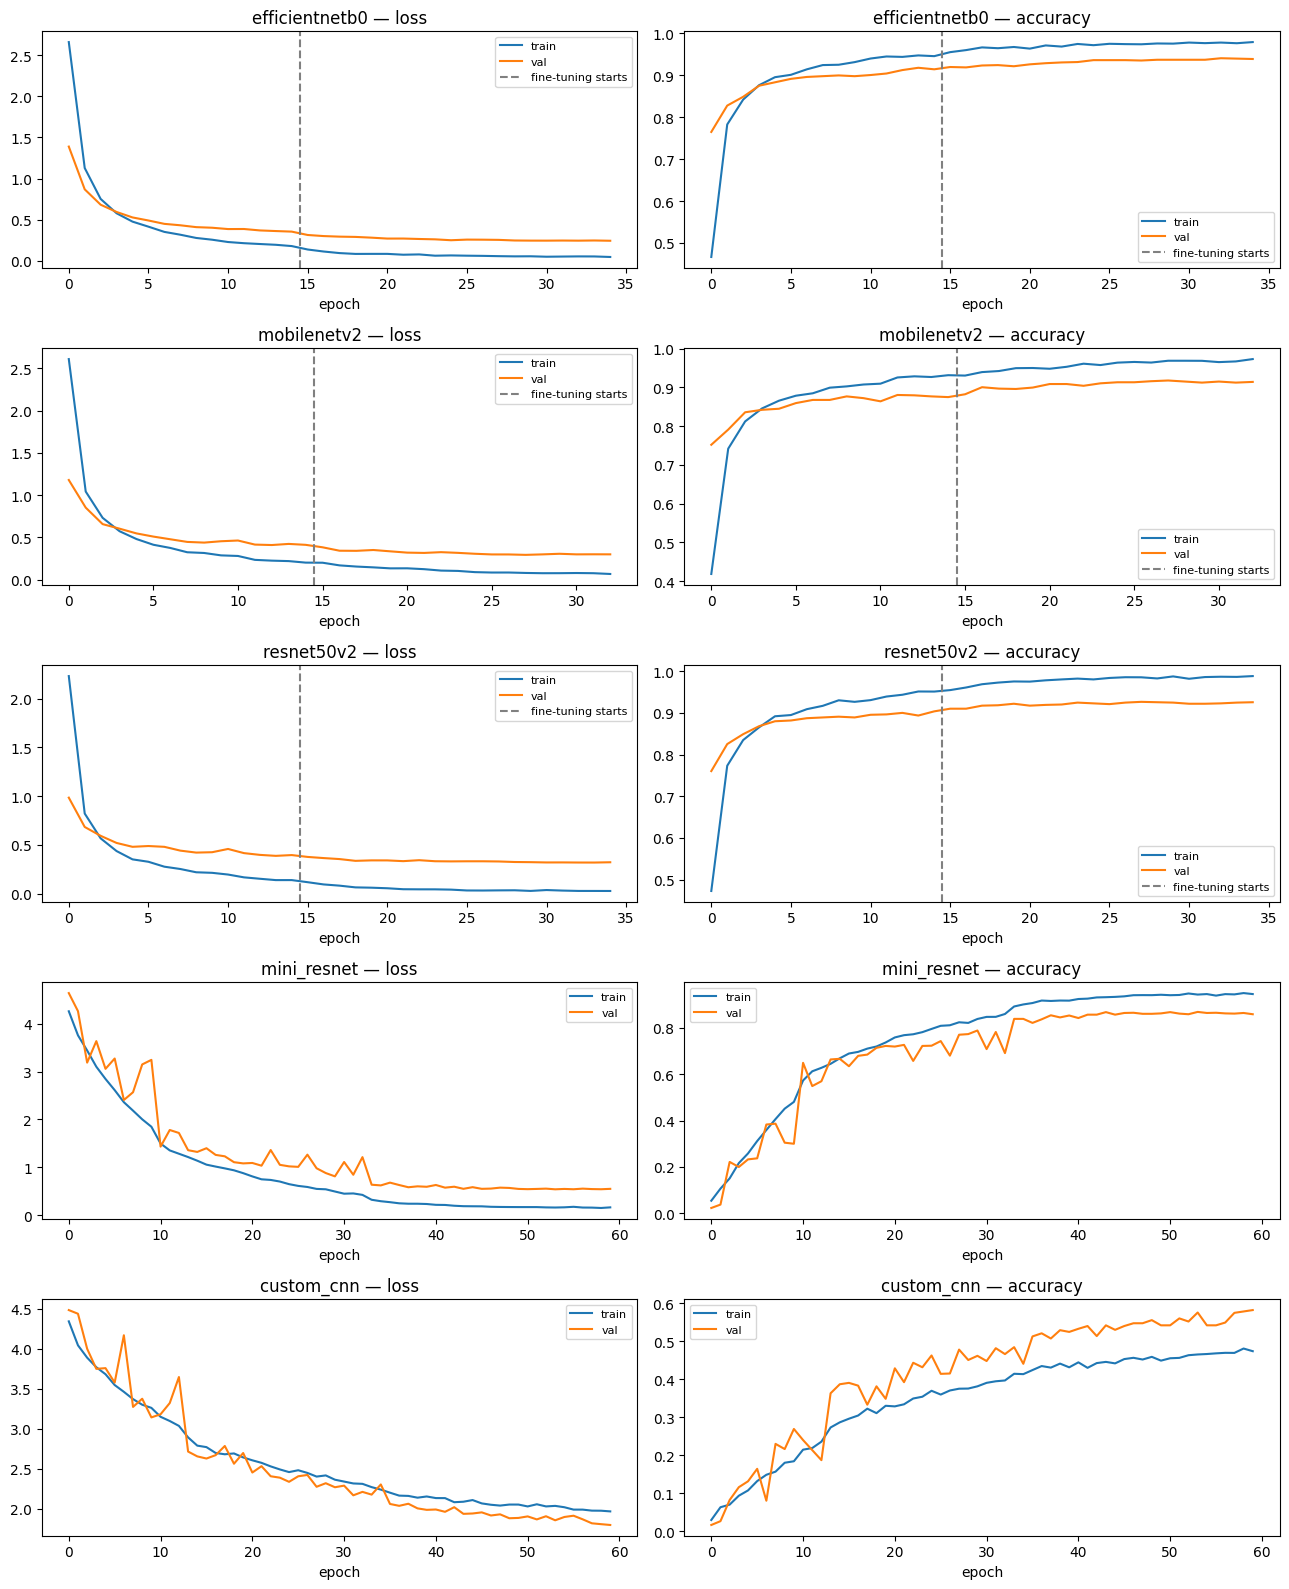

In [ ]:
fig, axes = plt.subplots(len(res), 2, figsize=(13, 3.2 * len(res)), squeeze=False)
for i, name in enumerate(res.model):
    with open(f"{RESULTS_DIR}/{name}_history.json") as f:
        h = json.load(f)
    for j, metric in enumerate(["loss", "accuracy"]):
        ax = axes[i, j]
        ax.plot(h["history"][metric], label="train")
        ax.plot(h["history"]["val_" + metric], label="val")
        if h["finetune_start"]:
            ax.axvline(h["finetune_start"] - 0.5, color="gray", ls="--", label="fine-tuning starts")
        ax.set_title(f"{name} — {metric}")
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Error analysis

Uses the best model; set MODEL_TO_INSPECT to look at another one.

efficientnetb0: accuracy 0.942

              precision    recall  f1-score   support

      OBJ001       0.93      1.00      0.97        14
      OBJ002       1.00      1.00      1.00        14
      OBJ003       0.79      1.00      0.88        15
      OBJ004       1.00      0.93      0.97        15
      OBJ005       0.94      1.00      0.97        15
      OBJ006       1.00      1.00      1.00        14
      OBJ007       1.00      1.00      1.00        14
      OBJ008       0.93      1.00      0.97        14
      OBJ009       0.93      1.00      0.97        14
      OBJ010       0.94      1.00      0.97        15
      OBJ011       0.88      1.00      0.93        14
      OBJ012       1.00      0.71      0.83        14
      OBJ013       0.71      0.80      0.75        15
      OBJ014       0.88      1.00      0.93        14
      OBJ015       1.00      0.93      0.97        15
      OBJ016       0.88      1.00      0.94        15
      OBJ017       1.00      1.00      1.00      

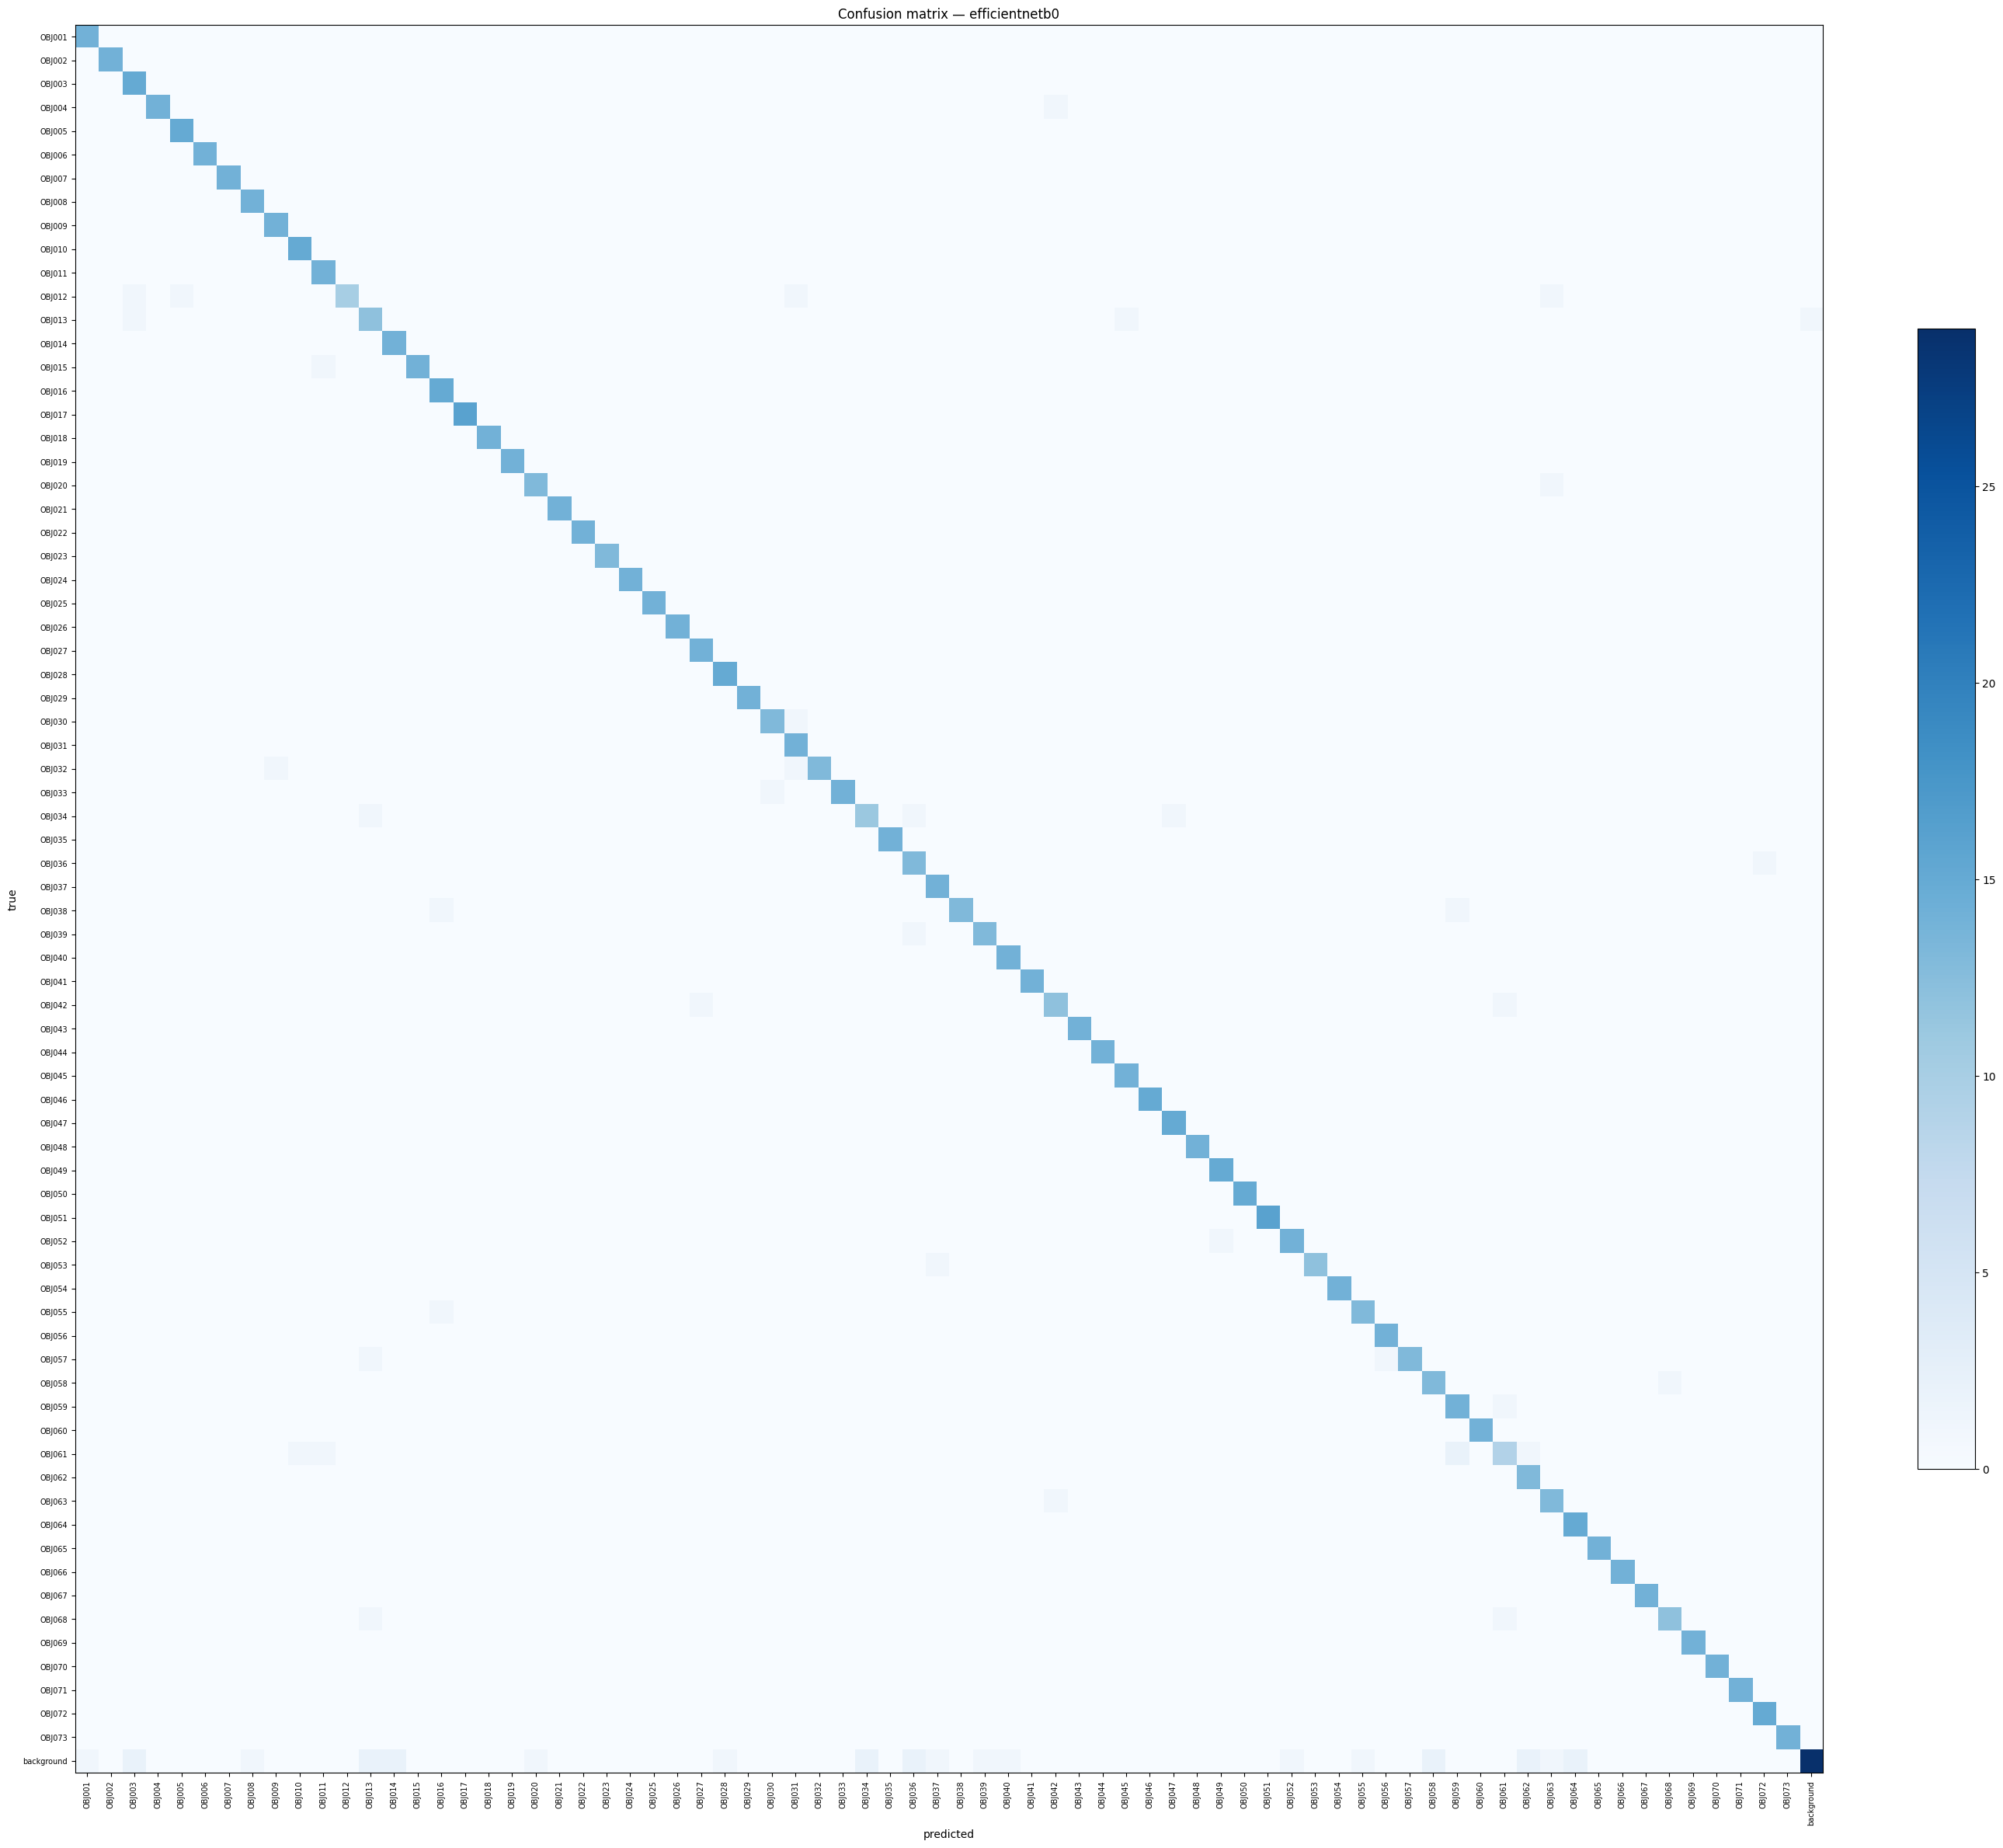

Most common mistakes (true -> predicted):
  background -> OBJ064: 2
  background -> OBJ062: 2
  background -> OBJ058: 2
  background -> OBJ036: 2
  background -> OBJ034: 2
  background -> OBJ014: 2
  background -> OBJ013: 2
  background -> OBJ003: 2
  OBJ061 -> OBJ059: 2
  background -> OBJ063: 1


In [ ]:
MODEL_TO_INSPECT = res.model.iloc[0]

y_true = test_df.label.map(class_to_idx).values
y_pred = np.load(f"{RESULTS_DIR}/{MODEL_TO_INSPECT}_pred.npy")
print(f"{MODEL_TO_INSPECT}: accuracy {accuracy_score(y_true, y_pred):.3f}\n")
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
size = max(6, NUM_CLASSES * 0.35)
plt.figure(figsize=(size, size))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=90, fontsize=7)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=7)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title(f"Confusion matrix — {MODEL_TO_INSPECT}")
plt.colorbar(fraction=0.03)
plt.tight_layout()
plt.show()

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
pairs = sorted(((off_diag[i, j], CLASS_NAMES[i], CLASS_NAMES[j])
                for i, j in zip(*np.nonzero(off_diag))), reverse=True)[:10]
print("Most common mistakes (true -> predicted):")
for n, true, pred in pairs:
    print(f"  {true} -> {pred}: {n}")

In [ ]:
wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} misclassified out of {len(y_true)}")

n = min(18, len(wrong))
n_rows = (n + 5) // 6
plt.figure(figsize=(15, 2.8 * n_rows))
for k, i in enumerate(wrong[:n]):
    plt.subplot(n_rows, 6, k + 1)
    plt.imshow(Image.open(test_df.path[i]))
    plt.title(f"true {CLASS_NAMES[y_true[i]]}\npred {CLASS_NAMES[y_pred[i]]}", fontsize=8, color="red")
    plt.axis("off")
plt.tight_layout()
plt.show()